# Praktikum 3 : pengaruh parameter C

In [1]:
# Langkah 1 - Import Library dan Buat Fungsi Plotting

# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

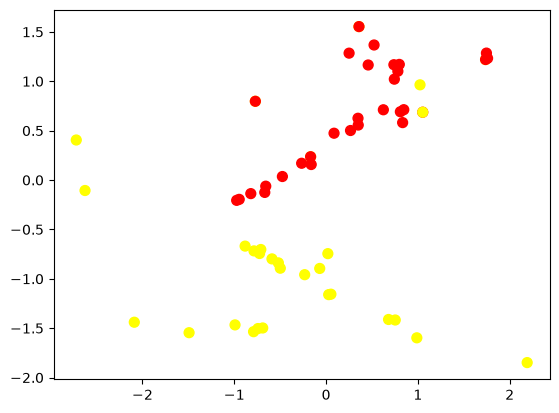

In [3]:
# Langkah 2 - Load data PBL
import pandas as pd
from sklearn.preprocessing import StandardScaler
data = pd.read_csv('../../dataset_pbl/cafes.csv')
data = data[data['source_query'].isin(['Cafe Soekarno Hatta Malang', 'Cafe Dinoyo Malang'])]
data = data.sample(frac=1, random_state=42).reset_index(drop=True)
X = StandardScaler().fit_transform(data[['latitude', 'longitude']])
y = data['source_query'].map({'Cafe Soekarno Hatta Malang': 0, 'Cafe Dinoyo Malang': 1}).to_numpy()
plt.scatter(X[:,0], X[:,1], c=y, s=50, cmap='autumn')

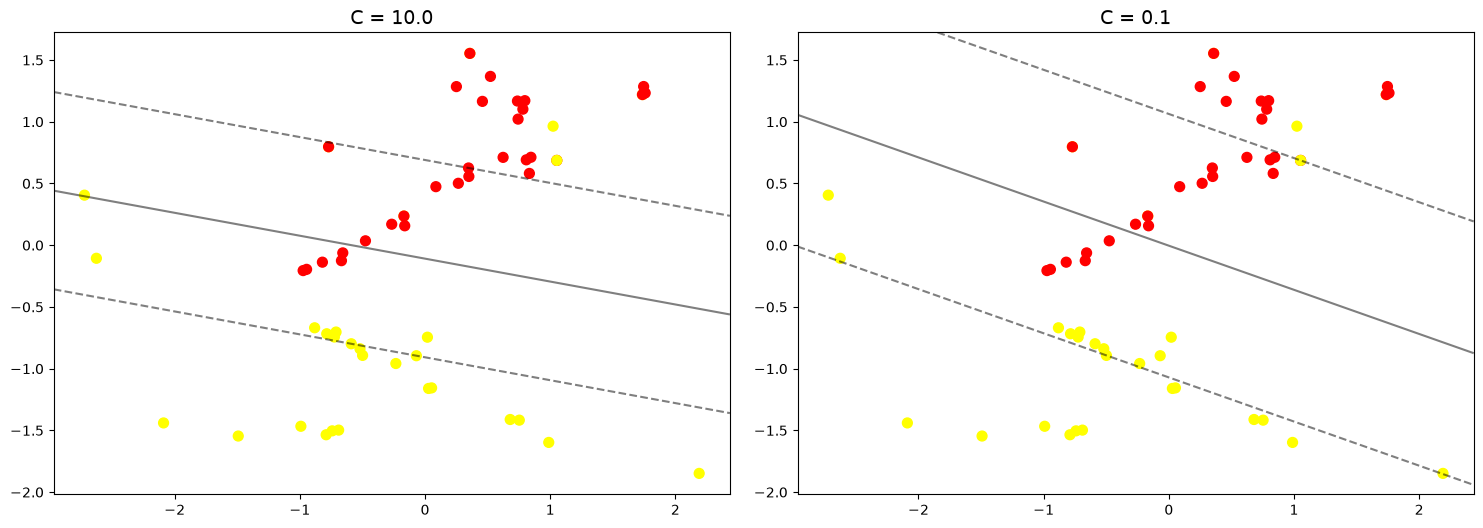

In [4]:
# Langkah 3 - Analisis Dampak Tunning



fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)